# Grafos — Olist

**Fase 4 de CRISP-DM · módulo de grafos**

Pregunta de negocio: ¿qué productos, categorías o vendedores están más conectados?

Este notebook consume los artefactos generados por `src/models/graphs.py` (no reentrena desde Streamlit).
El grafo principal es el **bipartito categoría–vendedor**, porque es el único 100% conexo y permite
detectar comunidades sin descartar nodos. La co-compra producto–producto se usa como análisis complementario.

In [1]:
import json
from pathlib import Path

import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "artifacts").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
ARTIFACTS = ROOT / "artifacts" / "graphs"

metricas = json.loads((ARTIFACTS / "metricas.json").read_text(encoding="utf-8"))
manifest = json.loads((ARTIFACTS / "manifest.json").read_text(encoding="utf-8"))
print("Modelo ganador:", manifest["winner"])
print("Periodo:", manifest["period"])

Modelo ganador: Louvain
Periodo: 2016-09-04 a 2018-09-03


## 1. Elección del grafo

Comparamos la conectividad de los tres candidatos. Un grafo con muchos nodos aislados no sirve para
detección de comunidades: Louvain no tiene información para agruparlos.

In [2]:
resumen = pd.DataFrame([
    {"grafo": "categoría–vendedor", **{k: metricas["grafo_principal"][k] for k in ["nodos", "aristas", "componentes", "componente_gigante_%", "grado_promedio"]}},
    {"grafo": "producto–vendedor", **{k: metricas["grafo_producto_vendedor"][k] for k in ["nodos", "aristas", "componentes", "componente_gigante_%", "grado_promedio"]}},
    {"grafo": "co-compra producto", **{k: metricas["grafo_co_compra"][k] for k in ["nodos", "aristas", "componentes", "componente_gigante_%", "grado_promedio"]}},
    {"grafo": "co-compra categoría", **{k: metricas["grafo_categoria_categoria"][k] for k in ["nodos", "aristas", "componentes", "componente_gigante_%", "grado_promedio"]}},
])
resumen

,grafo,nodos,aristas,componentes,componente_gigante_%,grado_promedio
0,categoría–vendedor,3169,6616,1,100.00,4.18
1,producto–vendedor,36046,34448,2423,26.94,1.91
2,co-compra producto,4885,4058,1652,8.15,1.66
3,co-compra categoría,64,262,1,100.00,8.19


## 2. Comparación de algoritmos de comunidades

Se comparan Louvain, Greedy Modularity y Label Propagation. El ganador se elige por modularidad;
si la diferencia es ≤ 0.001 (empate técnico), gana el más rápido.

In [3]:
pd.DataFrame(metricas["comparacion_comunidades"]).sort_values("modularidad", ascending=False)

,algoritmo,modularidad,comunidades,cobertura,tiempo_s
1,Greedy Modularity,0.7600,21,1.0,4.64
0,Louvain,0.7596,21,1.0,0.11
2,Label Propagation,0.4059,55,1.0,0.08


## 3. Comunidades detectadas

Cada comunidad mezcla categorías y vendedores. Las comunidades grandes con muchas categorías
suelen representar surtidos amplios; las pequeñas, vendedores especializados.

In [4]:
comunidades = pd.read_csv(ARTIFACTS / "comunidades.csv")
comunidades.head(10)

,comunidad,nodos,categorias,vendedores,grado_promedio,top_nodos
0,14,391,2,389,3.48,"health_beauty, perfumery, 44073f8b7e41514de3b7..."
1,11,332,6,326,3.77,"sports_leisure, drinks, food_drink, 1da3aeb70d..."
2,7,317,6,311,4.77,"toys, baby, stationery, luggage_accessories, b..."
3,9,302,7,295,3.91,"furniture_decor, home_construction, furniture_..."
4,1,264,5,259,4.63,"housewares, industry_commerce_and_business, f8..."
5,8,244,4,240,3.46,"auto, food, christmas_supplies, fashion_shoes,..."
6,6,174,3,171,4.67,"computers_accessories, consoles_games, 4e92295..."
7,4,139,8,131,4.86,"small_appliances, air_conditioning, kitchen_di..."
8,17,125,4,121,3.64,"bed_bath_table, home_confort, dd2bdf855a917273..."
9,3,116,3,113,4.51,"watches_gifts, fashion_bags_accessories, audio..."


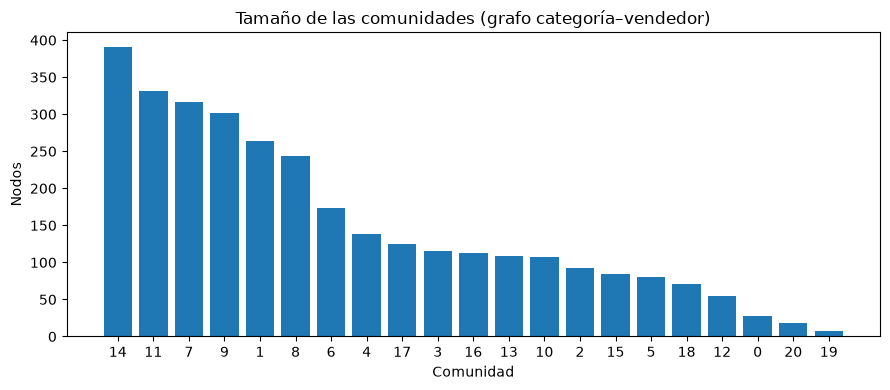

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(comunidades.comunidad.astype(str), comunidades.nodos)
ax.set_xlabel("Comunidad")
ax.set_ylabel("Nodos")
ax.set_title("Tamaño de las comunidades (grafo categoría–vendedor)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Centralidad

- **Grado:** popularidad (número de conexiones).
- **PageRank:** importancia considerando la importancia de los vecinos.
- **Betweenness aproximada:** nodos puente entre comunidades.

In [6]:
print("Categorías con más vendedores:")
display(pd.DataFrame(metricas["top_categorias_por_vendedores"]))
print("Vendedores con más categorías:")
display(pd.DataFrame(metricas["top_vendedores_por_categorias"]))

Categorías con más vendedores:


,nodo,grado
0,health_beauty,492
1,sports_leisure,481
2,housewares,468
3,auto,383
4,furniture_decor,370
5,computers_accessories,287
6,cool_stuff,267
7,sin_categoria,257
8,toys,252
9,baby,244


Vendedores con más categorías:


,nodo,grado
0,b2ba3715d723d245138f291a6fe42594,27
1,4e922959ae960d389249c378d1c939f5,24
2,955fee9216a65b617aa5c0531780ce60,23
3,1da3aeb70d7989d1e6d9b0e887f97c23,21
4,f8db351d8c4c4c22c6835c19a46f01b0,20
5,18a349e75d307f4b4cc646a691ed4216,17
6,44073f8b7e41514de3b7815dd0237f4f,15
7,6edacfd9f9074789dad6d62ba7950b9c,15
8,70a12e78e608ac31179aea7f8422044b,15
9,2ff97219cb8622eaf3cd89b7d9c09824,14


In [7]:
print("Productos con mayor PageRank (grafo producto–vendedor):")
display(pd.DataFrame(metricas["top_productos_pagerank"]))
print("Nodos con mayor betweenness aproximada:")
display(pd.DataFrame(metricas["betweenness_aproximada"]))

Productos con mayor PageRank (grafo producto–vendedor):


,producto,categoria,pagerank,grado
0,99a4788cb24856965c36a24e339b6058,bed_bath_table,0.001103,2
1,aca2eb7d00ea1a7b8ebd4e68314663af,furniture_decor,0.000425,1
2,53b36df67ebb7c41585e8d54d6772e08,watches_gifts,0.000411,3
3,35afc973633aaeb6b877ff57b2793310,home_confort,0.000377,2
4,06edb72f1e0c64b14c5b79353f7abea3,bed_bath_table,0.000346,1
5,e0d64dcfaa3b6db5c54ca298ae101d05,watches_gifts,0.000300,5
6,d285360f29ac7fd97640bf0baef03de0,watches_gifts,0.000286,8
7,e44f675b60b3a3a2453ec36421e06f0f,sports_leisure,0.000285,3
8,bee2e070c39f3dd2f6883a17a5f0da45,computers_accessories,0.000265,1
9,78efe838c04bbc568be034082200ac20,furniture_decor,0.000264,1


Nodos con mayor betweenness aproximada:


,nodo,betweenness
0,b2ba3715d723d245138f291a6fe42594,0.406015
1,612170e34b97004b3ba37eae81836b4c,0.249372
2,46dc3b2cc0980fb8ec44634e21d2718e,0.229972
3,2eb70248d66e0e3ef83659f71b244378,0.202772
4,8444e55c1f13cd5c179851e5ca5ebd00,0.202381
5,22a8168cf1f1c6347da8d29863b7f75e,0.190821
6,44073f8b7e41514de3b7815dd0237f4f,0.162640
7,2b2cde418c199f2ad971a7511cac11c0,0.154948
8,620c87c171fb2a6dd6e8bb4dec959fc6,0.148151
9,8b28d096634035667e8263d57ba3368c,0.143787


## 5. Co-compra: análisis complementario

Solo 3,236 pedidos tienen dos o más productos distintos, por lo que este grafo es disperso.
Se usa para detectar oportunidades de venta cruzada, no como base del módulo.

In [8]:
print("Pares de categorías que más se compran juntas:")
display(pd.DataFrame(metricas["top_pares_categorias"]))
print("Pares de productos que más se compran juntos:")
display(pd.DataFrame(metricas["top_pares_co_compra"]))

Pares de categorías que más se compran juntas:


,categoria_a,categoria_b,pedidos
0,bed_bath_table,furniture_decor,70
1,bed_bath_table,home_confort,43
2,housewares,furniture_decor,24
3,baby,cool_stuff,20
4,bed_bath_table,housewares,20
5,toys,baby,19
6,baby,bed_bath_table,17
7,garden_tools,furniture_decor,17
8,housewares,sin_categoria,14
9,sports_leisure,health_beauty,14


Pares de productos que más se compran juntos:


,producto_a,producto_b,pedidos
0,36f60d45225e60c7da4558b070ce4b60,e53e557d5a159f5aa2c5e995dfdf244b,34
1,99a4788cb24856965c36a24e339b6058,35afc973633aaeb6b877ff57b2793310,29
2,4fcb3d9a5f4871e8362dfedbdb02b064,f4f67ccaece962d013a4e1d7dc3a61f7,17
3,36f60d45225e60c7da4558b070ce4b60,3f14d740544f37ece8a9e7bc8349797e,12
4,389d119b48cf3043d311335e499d9c6b,422879e10f46682990de24d770e7f83d,11
5,389d119b48cf3043d311335e499d9c6b,53759a2ecddad2bb87a079a1f1519f73,9
6,53759a2ecddad2bb87a079a1f1519f73,368c6c730842d78016ad823897a372db,8
7,18486698933fbb64af6c0a255f7dd64c,dbb67791e405873b259e4656bf971246,7
8,53759a2ecddad2bb87a079a1f1519f73,422879e10f46682990de24d770e7f83d,7
9,060cb19345d90064d1015407193c233d,98d61056e0568ba048e5d78038790e77,6


## 6. Conclusiones y limitaciones

In [9]:
for conclusion in manifest["business_conclusions"]:
    print("•", conclusion)
print()
for limitation in manifest["limitations"]:
    print("⚠", limitation)

• El grafo categoría–vendedor está 100.0% conectado, por lo que permite analizar todas las categorías y vendedores sin descartar nodos.
• health_beauty es la categoría con más vendedores (492), seguida de sports_leisure (481), lo que indica mercados con mayor competencia.
• La co-compra de categorías más frecuente es bed_bath_table + furniture_decor (70 pedidos), una oportunidad de venta cruzada.
• Solo 3,236 pedidos incluyen dos o más productos distintos, por lo que el grafo de co-compra directa es disperso y debe complementarse con reglas de asociación.

⚠ El grafo de co-compra producto–producto es disperso: el componente gigante cubre 8.15% de sus nodos.
⚠ Las aristas categoría–vendedor representan presencia, no volumen de ventas ni ingresos.
⚠ El periodo analizado (2016-09-04 a 2018-09-03) no refleja el comportamiento actual del mercado.
⚠ Louvain es estocástico; se fijó random_state=42 para reproducibilidad.
⚠ Betweenness se calculó de forma aproximada (k=100) sobre el componente 